# Time-sliced models

Features at a cutoff are static demographics plus everything the VLE and the assessment calendar have revealed by that day: total clicks, clicks by activity type, clicks in the last seven days, clicks before the start date, days since the last click, assessment scores submitted by then, how many scheduled assessments are already due, and whether the first tutor-marked assignment is missing or late.

Two models, no search beyond a three-point grid. Logistic regression is the linear baseline. LightGBM is the main model. Tree count, learning rate and number of leaves are chosen on 2013J after fitting on 2013B. 2014 is not used for that choice.

Three evaluations:

- **Temporal.** Train on 2013B and 2013J, test on 2014B and 2014J. This is the number to quote.
- **Random row split.** One stratified 70/30 cut of rows. The same presentation, and sometimes the same student, appears on both sides.
- **Leave one module out.** Train on the other six modules, test on the held-out module. This is module transfer, not a time shift. The headline is a weighted average. The shaded band is the best and worst module.

Recall is not "top 20% of the whole university". Each module flags its own top 20%. Otherwise a difficult module would consume the list. PR-AUC and ROC-AUC stay global for a single model, because those scores are on one scale. Leave-one-module-out averages the per-module areas, weighted by test size, for the same reason: scores from seven different models are not comparable as one ranking.


In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))

from oulad.config import CACHE_VERSION, FIG_DIR, PROC_DIR, REPORT_DIR

from oulad.features import feature_columns
from oulad.metrics import pool_metrics

features = pd.read_parquet(PROC_DIR / f"features_{CACHE_VERSION}_c28_active.parquet")
columns = feature_columns(features)
print(f"{len(features):,} students still enrolled at day 28")
print(f"{len(columns)} features")
print(", ".join(columns))


27,538 students still enrolled at day 28
45 features
age_band, code_module, date_registration, disability, gender, highest_education, imd_band, num_of_prev_attempts, region, studied_credits, active_days, clicks_last_7d, clicks_prestart, clicks_total, clicks_type_dataplus, clicks_type_dualpane, clicks_type_externalquiz, clicks_type_folder, clicks_type_forumng, clicks_type_glossary, clicks_type_homepage, clicks_type_htmlactivity, clicks_type_oucollaborate, clicks_type_oucontent, clicks_type_ouelluminate, clicks_type_ouwiki, clicks_type_page, clicks_type_questionnaire, clicks_type_quiz, clicks_type_repeatactivity, clicks_type_resource, clicks_type_sharedsubpage, clicks_type_subpage, clicks_type_url, days_since_last_click, never_active, asmt_mean_score, asmt_min_score, first_tma_days_late, first_tma_due, first_tma_missing, first_tma_score, n_due, n_submitted_due, submit_rate


In [2]:
metrics = pd.read_csv(REPORT_DIR / "metrics.csv")
show = metrics.loc[metrics["split"].isin(["temporal", "random", "lomo", "temporal_seen_modules", "temporal_unseen_modules", "temporal_keep_withdrawn"])]
cols = ["cutoff", "split", "model", "pr_auc", "roc_auc", "recall_at_20", "base_rate", "n_test", "n_train", "student_overlap", "presentation_overlap"]
show = show.loc[:, [c for c in cols if c in show.columns]].sort_values(["model", "split", "cutoff"])
show.round(3)


,cutoff,split,model,pr_auc,roc_auc,recall_at_20,base_rate,n_test,n_train,student_overlap,presentation_overlap
5,0,lomo,lgbm,0.669,0.697,0.303,0.478,29496,25282,0.159,0.0
11,14,lomo,lgbm,0.675,0.717,0.325,0.453,28119,24102,0.155,0.0
17,28,lomo,lgbm,0.724,0.763,0.346,0.441,27538,23604,0.150,0.0
23,56,lomo,lgbm,0.759,0.799,0.386,0.420,26522,22733,0.143,0.0
29,84,lomo,lgbm,0.799,0.829,0.429,0.402,25724,22049,0.140,0.0
3,0,random,lgbm,0.696,0.722,0.309,0.478,8849,20647,0.152,1.0
9,14,random,lgbm,0.715,0.744,0.332,0.453,8436,19683,0.150,1.0
15,28,random,lgbm,0.778,0.795,0.374,0.441,8262,19276,0.141,1.0
21,56,random,lgbm,0.808,0.830,0.415,0.420,7957,18565,0.129,1.0
27,84,random,lgbm,0.830,0.852,0.447,0.402,7718,18006,0.126,1.0


In [3]:
# Recompute the day-28 temporal LightGBM numbers from the saved scores.
scores = pd.read_parquet(PROC_DIR / "scores" / CACHE_VERSION / "temporal_lgbm_c28.parquet")
stats = pool_metrics(scores)
quoted = metrics.loc[
    (metrics["split"] == "temporal") & (metrics["model"] == "lgbm") & (metrics["cutoff"] == 28)
].iloc[0]
print("recomputed PR-AUC", round(stats["pr_auc"], 4), "table", round(quoted["pr_auc"], 4))
print("recomputed recall@20", round(stats["recall_at_20"], 4), "table", round(quoted["recall_at_20"], 4))
assert abs(stats["pr_auc"] - quoted["pr_auc"]) < 1e-9
assert abs(stats["recall_at_20"] - quoted["recall_at_20"]) < 1e-9
print("student overlap, temporal test rows whose id is also in train:", round(float(scores["student_overlap"].iloc[0]), 3))
print("share of temporal test rows from a presentation seen in train:", round(float(scores["presentation_overlap"].iloc[0]), 3))


recomputed PR-AUC 0.722 table 0.722
recomputed recall@20 0.3551 table 0.3551
student overlap, temporal test rows whose id is also in train: 0.093
share of temporal test rows from a presentation seen in train: 0.0


The random split shares presentations with the training rows, so it can learn "this run of BBB is hard". The temporal split shares none of the presentation codes. Some student ids still repeat, because people take more than one module; that overlap is reported above and is not removed.

The sensitivity row `temporal_keep_withdrawn` is the day-28 model with students who have already unregistered left in the data. They are easy to spot, because they have stopped clicking and the label is already Withdrawn. That row is not the system. It is the cost of getting the cohort wrong.

`temporal_unseen_modules` is the 2014 test restricted to modules with no 2013 presentation (CCC). `temporal_seen_modules` is the rest.


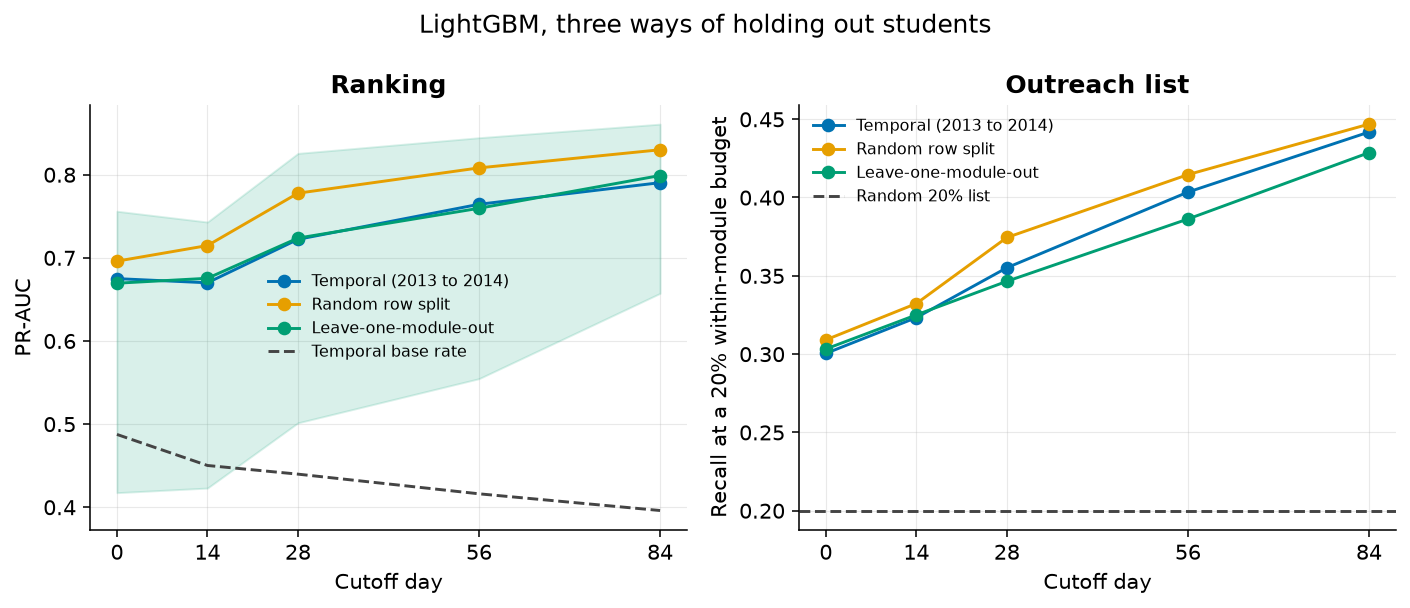

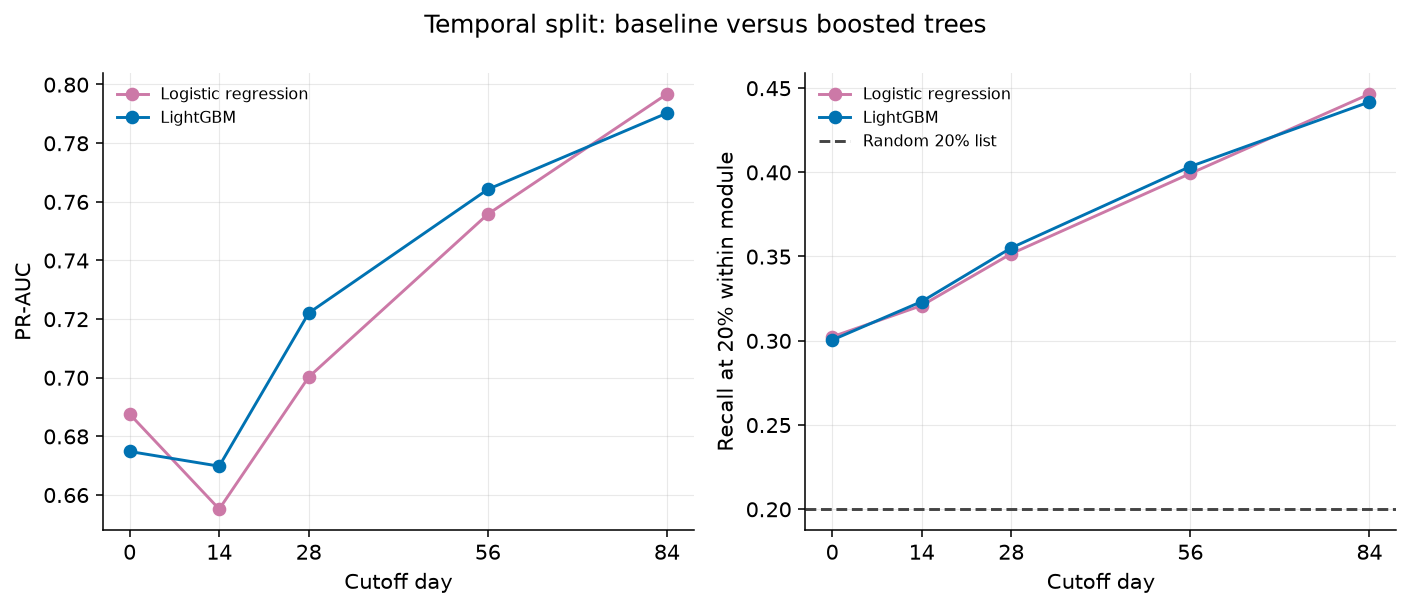

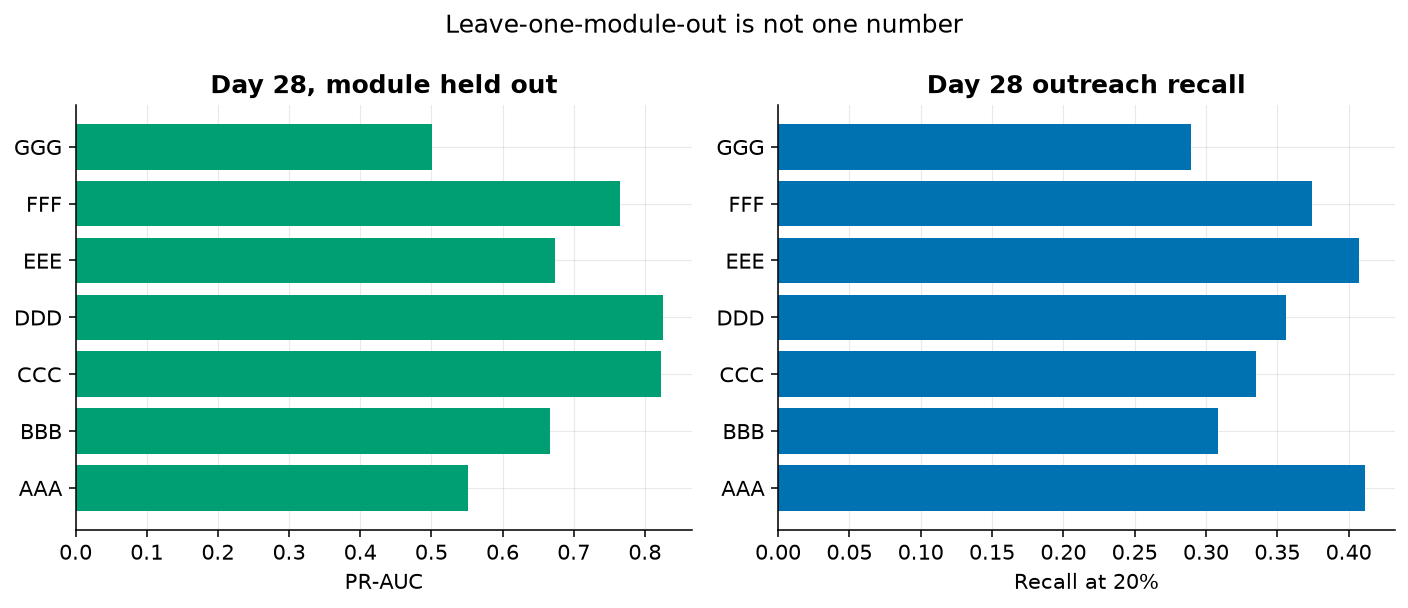

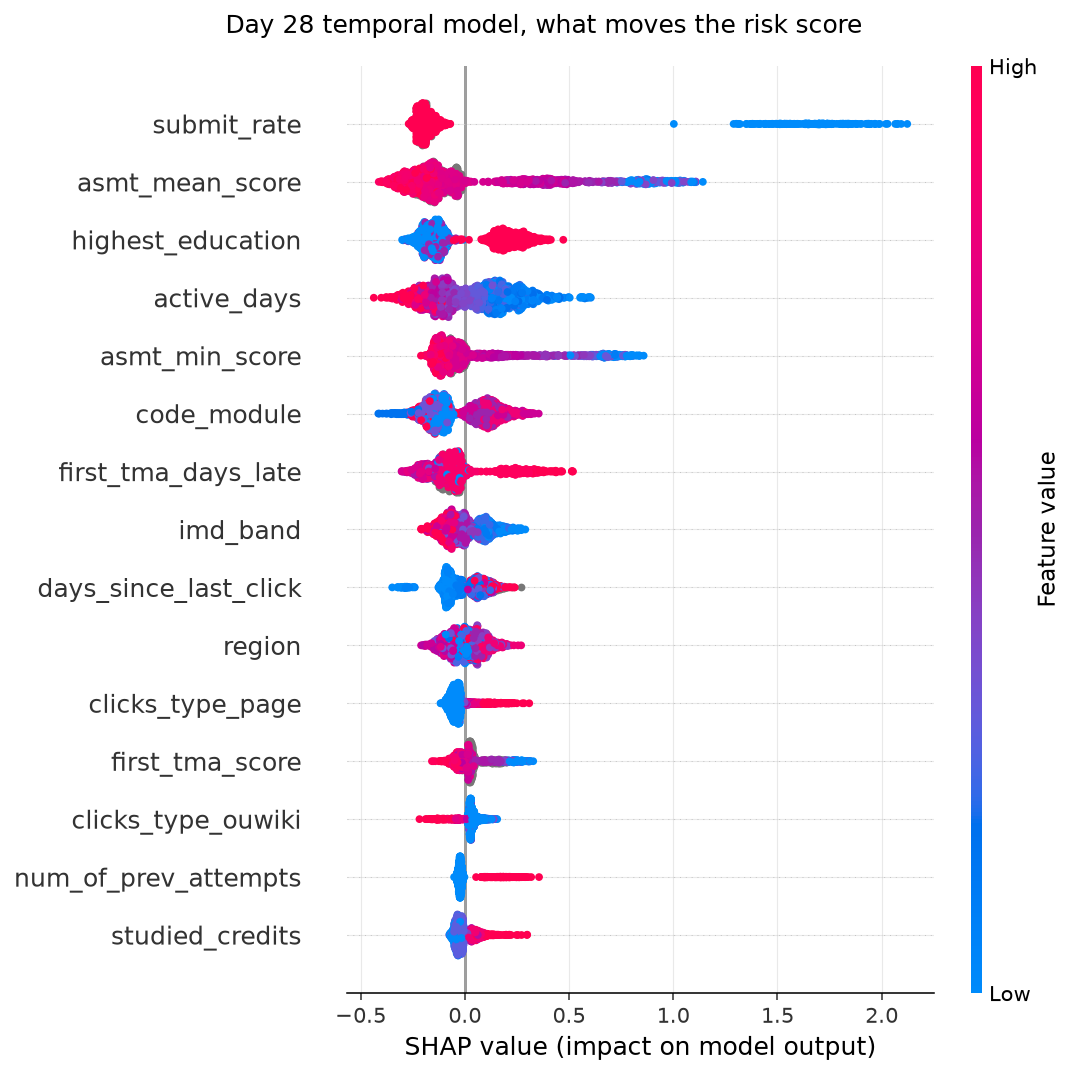

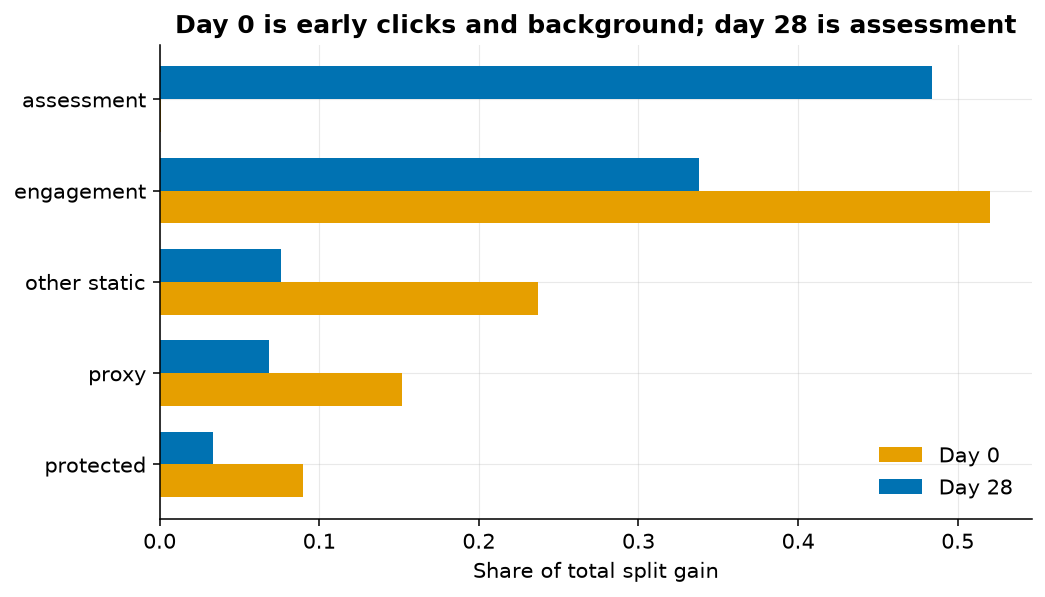

In [4]:
for name in ("metric_vs_cutoff", "model_comparison", "lomo_by_module", "shap_day28", "importance_day0_vs_day28"):
    display(Image(filename=str(FIG_DIR / f"{name}.png")))


Day 0 has registration, demographics, and clicks from before the start date. It does not yet have an assessment. The gain chart splits features into protected attributes (gender, age, disability, deprivation), proxies (region, prior education), other static fields, engagement, and assessment. On this data the day-0 gain is mostly pre-start clicks, with protected attributes a small share. By day 28 the gain has moved to assessment behaviour. The fairness section asks who that later list still misses.
